## Comprehensive Restaurant Health Inspection Profile

This section summarizes inspection volume, scores, grades, enforcement outcomes, violation severity, violation-code frequency, and text themes. Metrics are computed at the inspection level unless explicitly described as violation-record metrics; this avoids treating each cited violation as a separate inspection.

- Placeholder records marked `AWAITING_INSPECTION` are excluded from inspection metrics.
- Score averages use inspections with a recorded `SCORE`. Grade shares use only inspections graded A, B, or C; pending and missing grades are reported separately in the distribution.
- DOHMH closure outcomes include initial closures and re-closures; re-openings are reported separately. These are action-code rates, not a causal or risk-adjusted measure.
- `NTA` is used as the neighborhood grouping. The map uses restaurant coordinates and does not display neighborhood boundary polygons.
- The dataset ends in August 2026, so 2026 is a partial year.

In [52]:
real_inspections = inspection_level_for_eda.copy()
scored_real_inspections = real_inspections.loc[real_inspections["SCORE"].notna()].copy()

overall_profile = pd.Series(
    {
        "inspection_period_start": real_inspections["INSPECTION DATE"].min(),
        "inspection_period_end": real_inspections["INSPECTION DATE"].max(),
        "total_real_inspections": len(real_inspections),
        "unique_restaurants_inspected": real_inspections["CAMIS"].nunique(),
        "inspections_with_score": len(scored_real_inspections),
        "average_score": scored_real_inspections["SCORE"].mean(),
        "median_score": scored_real_inspections["SCORE"].median(),
        "score_standard_deviation": scored_real_inspections["SCORE"].std(),
    },
    name="value",
).to_frame()

grade_distribution = (
    real_inspections.assign(grade=real_inspections["GRADE"].fillna("Missing"))
    .groupby("grade")
    .size()
    .rename("inspection_count")
    .reset_index()
)
grade_distribution["share_of_all_inspections"] = (
    grade_distribution["inspection_count"] / len(real_inspections)
)

known_actions = real_inspections.loc[real_inspections["ACTION"].notna()].copy()
known_actions["dohmh_closed_or_reclosed"] = known_actions["ACTION"].str.contains(
    r"Establishment (?:re-)?closed by DOHMH", case=False, regex=True, na=False
)
known_actions["dohmh_reopened"] = known_actions["ACTION"].str.contains(
    "Establishment re-opened by DOHMH", case=False, regex=False, na=False
)
action_outcomes = (
    known_actions["ACTION"].value_counts()
    .rename_axis("action")
    .reset_index(name="inspection_count")
)
action_outcomes["share_of_inspections_with_action"] = (
    action_outcomes["inspection_count"] / len(known_actions)
)
dohmh_action_rates = pd.DataFrame(
    {
        "action_outcome": ["closed_or_reclosed", "reopened"],
        "inspection_count": [
            int(known_actions["dohmh_closed_or_reclosed"].sum()),
            int(known_actions["dohmh_reopened"].sum()),
        ],
    }
)
dohmh_action_rates["rate_among_inspections_with_action"] = (
    dohmh_action_rates["inspection_count"] / len(known_actions)
)

inspection_class = real_inspections["INSPECTION TYPE"].str.extract(
    r"/\s*(Initial Inspection|Re-inspection)$", expand=False
)
initial_reinspection = real_inspections.assign(
    inspection_class=inspection_class
).dropna(subset=["inspection_class"])
initial_reinspection_summary = (
    initial_reinspection.groupby("inspection_class")
    .agg(
        total_inspections=("CAMIS", "size"),
        inspections_with_score=("SCORE", "count"),
        average_score=("SCORE", "mean"),
        median_score=("SCORE", "median"),
        graded_inspections=("GRADE", lambda grades: grades.isin(["A", "B", "C"]).sum()),
        a_grade_inspections=("GRADE", lambda grades: grades.eq("A").sum()),
    )
    .reset_index()
)
initial_reinspection_summary["a_grade_share_among_graded"] = (
    initial_reinspection_summary["a_grade_inspections"]
    / initial_reinspection_summary["graded_inspections"]
)

scored_known_borough = scored_real_inspections.loc[
    scored_real_inspections["BORO"].notna()
    & ~scored_real_inspections["BORO_UNKNOWN"]
]
borough_summary = (
    scored_known_borough.groupby("BORO")
    .agg(
        scored_inspections=("SCORE", "count"),
        restaurants=("CAMIS", "nunique"),
        average_score=("SCORE", "mean"),
        median_score=("SCORE", "median"),
        graded_inspections=("GRADE", lambda grades: grades.isin(["A", "B", "C"]).sum()),
        a_grade_inspections=("GRADE", lambda grades: grades.eq("A").sum()),
    )
    .reset_index()
)
borough_summary["a_grade_share_among_graded"] = (
    borough_summary["a_grade_inspections"] / borough_summary["graded_inspections"]
)

neighborhood_summary = (
    scored_real_inspections.loc[scored_real_inspections["NTA"].notna()]
    .groupby(["BORO", "NTA"])
    .agg(
        scored_inspections=("SCORE", "count"),
        average_score=("SCORE", "mean"),
        median_score=("SCORE", "median"),
    )
    .reset_index()
    .sort_values("scored_inspections", ascending=False)
)

print("Overall profile")
display(overall_profile)
print("Grade distribution (including missing and pending grades)")
display(grade_distribution.sort_values("grade"))
print("DOHMH action outcomes")
display(dohmh_action_rates)
print("Initial inspection vs. re-inspection")
display(initial_reinspection_summary)
print("Score and A-grade share by borough")
display(borough_summary)
print("Neighborhoods with the most scored inspections")
display(neighborhood_summary.head(20))

Overall profile


,value
inspection_period_start,2007-08-10 00:00:00
inspection_period_end,2026-08-24 00:00:00
total_real_inspections,93292
unique_restaurants_inspected,27652
inspections_with_score,82956
average_score,17.890388
median_score,13.0
score_standard_deviation,14.922439


Grade distribution (including missing and pending grades)


,grade,inspection_count,share_of_all_inspections
0,A,44817,0.480395
1,B,4347,0.046596
2,C,2285,0.024493
3,Missing,37920,0.406466
4,N,2236,0.023968
5,P,548,0.005874
6,Z,1139,0.012209


DOHMH action outcomes


,action_outcome,inspection_count,rate_among_inspections_with_action
0,closed_or_reclosed,1908,0.020452
1,reopened,1264,0.013549


... (2 outputs left out)

Score and A-grade share by borough


,BORO,scored_inspections,restaurants,average_score,median_score,graded_inspections,a_grade_inspections,a_grade_share_among_graded
0,Bronx,7706,2425,17.574358,13.0,4834,4132,0.854779
1,Brooklyn,21412,7075,17.972305,12.0,13272,11594,0.873568
2,Manhattan,31393,10849,17.205906,12.0,19742,17514,0.887144
3,Queens,19429,6266,19.192187,13.0,11742,9934,0.846023
4,Staten Island,2922,1000,16.870979,12.5,1791,1585,0.884980


Neighborhoods with the most scored inspections


,BORO,NTA,scored_inspections,average_score,median_score
99,Manhattan,MN17,5288,16.386914,12.0
96,Manhattan,MN13,2602,16.383167,12.0
104,Manhattan,MN23,2430,16.676543,12.0
105,Manhattan,MN24,2276,16.827768,12.0
107,Manhattan,MN27,1875,19.158400,13.0
103,Manhattan,MN22,1692,17.546099,13.0
133,Queens,QN22,1649,23.154033,19.0
98,Manhattan,MN15,1575,17.452063,12.0
106,Manhattan,MN25,1557,15.838150,12.0
100,Manhattan,MN19,1551,16.328820,12.0


,BORO,inspections_with_action,dohmh_closures,dohmh_closure_rate
1,Brooklyn,23871,624,0.026141
3,Queens,22120,511,0.023101
0,Bronx,8509,142,0.016688
2,Manhattan,35549,590,0.016597
4,Staten Island,3141,38,0.012098


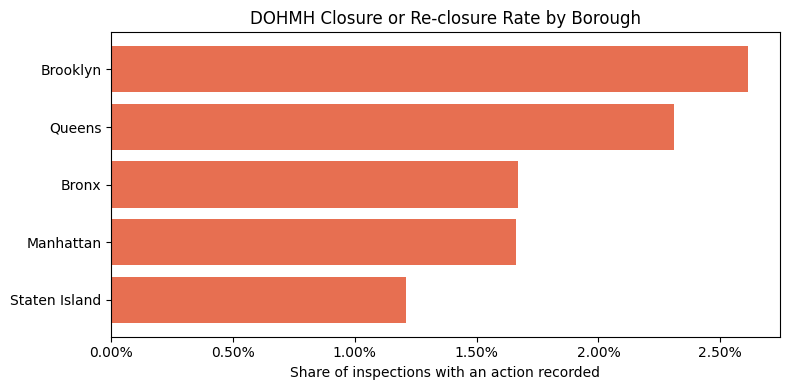

In [58]:
borough_actions = real_inspections.loc[
    real_inspections["BORO"].notna()
    & ~real_inspections["BORO_UNKNOWN"]
    & real_inspections["ACTION"].notna()
].copy()
borough_actions["dohmh_closed_or_reclosed"] = borough_actions["ACTION"].str.contains(
    r"Establishment (?:re-)?closed by DOHMH", case=False, regex=True, na=False
)
borough_action_rates = (
    borough_actions.groupby("BORO")
    .agg(
        inspections_with_action=("ACTION", "size"),
        dohmh_closures=("dohmh_closed_or_reclosed", "sum"),
    )
    .assign(
        dohmh_closure_rate=lambda data: (
            data["dohmh_closures"] / data["inspections_with_action"]
        )
    )
    .reset_index()
    .sort_values("dohmh_closure_rate", ascending=False)
)
display(borough_action_rates)

fig, ax = plt.subplots(figsize=(8, 4))
closure_plot = borough_action_rates.sort_values("dohmh_closure_rate")
ax.barh(
    closure_plot["BORO"],
    closure_plot["dohmh_closure_rate"],
    color="#e76f51",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("DOHMH Closure or Re-closure Rate by Borough")
ax.set_xlabel("Share of inspections with an action recorded")
fig.tight_layout()
plt.show()

### Violation Severity and Code Patterns

Violation frequencies are calculated from non-placeholder source rows with a violation code. For code-level inspection rates, repeated rows for the same code within an inspection are counted once. Per-inspection violation totals include inspections with no coded violations as zero.

In [54]:
violation_rows = df_prepared.loc[
    ~df_prepared["AWAITING_INSPECTION"] & df_prepared["VIOLATION CODE"].notna()
].copy()

severity_summary = (
    violation_rows["CRITICAL FLAG"]
    .fillna("Missing")
    .value_counts()
    .rename_axis("severity")
    .reset_index(name="violation_records")
)
classified_severity = severity_summary["severity"].isin(["Critical", "Not Critical"])
classified_violation_count = severity_summary.loc[
    classified_severity, "violation_records"
].sum()
severity_summary["share_of_classified_violation_records"] = severity_summary.apply(
    lambda row: (
        row["violation_records"] / classified_violation_count
        if row["severity"] in ["Critical", "Not Critical"]
        else pd.NA
    ),
    axis=1,
)

unique_inspection_codes = violation_rows.drop_duplicates(
    subset=inspection_key + ["VIOLATION CODE"]
)
code_record_summary = (
    violation_rows.groupby("VIOLATION CODE")
    .agg(
        violation_records=("VIOLATION CODE", "size"),
        description=("VIOLATION DESCRIPTION", "first"),
    )
    .reset_index()
)
code_inspection_summary = (
    unique_inspection_codes.groupby("VIOLATION CODE")
    .size()
    .rename("inspections_citing_code")
    .reset_index()
)
top_violation_codes = (
    code_record_summary.merge(code_inspection_summary, on="VIOLATION CODE")
    .assign(
        share_of_real_inspections=lambda data: (
            data["inspections_citing_code"] / len(real_inspections)
        ),
        inspections_per_1000=lambda data: (
            data["inspections_citing_code"] / len(real_inspections) * 1000
        ),
    )
    .sort_values("inspections_citing_code", ascending=False)
    .reset_index(drop=True)
)

inspection_violation_counts = (
    unique_inspection_codes.groupby(inspection_key)
    .agg(
        unique_violation_codes=("VIOLATION CODE", "nunique"),
        critical_violation_codes=("CRITICAL FLAG", lambda flags: flags.eq("Critical").sum()),
        non_critical_violation_codes=(
            "CRITICAL FLAG", lambda flags: flags.eq("Not Critical").sum()
        ),
    )
    .reset_index()
)
inspection_violation_profile = real_inspections[inspection_key].merge(
    inspection_violation_counts,
    on=inspection_key,
    how="left",
    validate="one_to_one",
)
violation_count_columns = [
    "unique_violation_codes",
    "critical_violation_codes",
    "non_critical_violation_codes",
]
inspection_violation_profile[violation_count_columns] = (
    inspection_violation_profile[violation_count_columns].fillna(0)
)
inspection_violation_profile["inspection_class"] = inspection_violation_profile[
    "INSPECTION TYPE"
].str.extract(r"/\s*(Initial Inspection|Re-inspection)$", expand=False)

violation_count_summary = pd.DataFrame(
    {
        "metric": [
            "average unique violation codes per inspection",
            "median unique violation codes per inspection",
            "inspections with no coded violations",
            "share of inspections with no coded violations",
        ],
        "value": [
            inspection_violation_profile["unique_violation_codes"].mean(),
            inspection_violation_profile["unique_violation_codes"].median(),
            int(inspection_violation_profile["unique_violation_codes"].eq(0).sum()),
            inspection_violation_profile["unique_violation_codes"].eq(0).mean(),
        ],
    }
)
violation_counts_by_class = (
    inspection_violation_profile.dropna(subset=["inspection_class"])
    .groupby("inspection_class")
    .agg(
        inspections=("CAMIS", "size"),
        average_unique_violation_codes=("unique_violation_codes", "mean"),
        median_unique_violation_codes=("unique_violation_codes", "median"),
        average_critical_codes=("critical_violation_codes", "mean"),
        average_non_critical_codes=("non_critical_violation_codes", "mean"),
    )
    .reset_index()
)

print("Critical vs. non-critical violation records")
display(severity_summary)
print("Average cited violation codes per inspection")
display(violation_count_summary)
print("Violation counts by inspection class")
display(violation_counts_by_class)
print("Top 15 violation codes by number of inspections citing the code")
display(top_violation_codes.head(15))

Critical vs. non-critical violation records


,severity,violation_records,share_of_classified_violation_records
0,Critical,155197,0.539658
1,Not Critical,132387,0.460342
2,Not Applicable,1815,<NA>


Average cited violation codes per inspection


,metric,value
0,average unique violation codes per inspection,3.102077
1,median unique violation codes per inspection,3.000000
2,inspections with no coded violations,2730.000000
3,share of inspections with no coded violations,0.029263


Violation counts by inspection class


,inspection_class,inspections,average_unique_violation_codes,median_unique_violation_codes,average_critical_codes,average_non_critical_codes
0,Initial Inspection,68002,3.118497,3.0,1.669819,1.425355
1,Re-inspection,22385,3.142908,3.0,1.713871,1.419745


Top 15 violation codes by number of inspections citing the code


,VIOLATION CODE,violation_records,description,inspections_citing_code,share_of_real_inspections,inspections_per_1000
0,10F,41293,Non-food contact surface or equipment made of ...,41293,0.442621,442.621018
1,08A,25270,Establishment is not free of harborage or cond...,25270,0.270870,270.869957
2,10B,18904,Anti-siphonage or back-flow prevention device ...,18904,0.202633,202.632594
3,02G,18901,Cold TCS food item held above 41 °F; smoked or...,18901,0.202600,202.600437
4,06C,18823,"Food, supplies, or equipment not protected fro...",18823,0.201764,201.764353
5,06D,18614,"Food contact surface not properly washed, rins...",18614,0.199524,199.524075
6,02B,15570,Hot TCS food item not held at or above 140 °F.,15570,0.166895,166.895339
7,04L,14229,Evidence of mice or live mice in establishment...,14229,0.152521,152.521116
8,04N,11088,Filth flies or food/refuse/sewage associated w...,11088,0.118853,118.852635
9,04A,7901,Food Protection Certificate (FPC) not held by ...,7901,0.084691,84.691077


### Trend and Grouped Visual Analytics

The charts below compare grade proportions, average scores, neighborhood volume, and frequently cited codes. Annual metrics use the inspection date; incomplete years should not be compared as full-year totals.

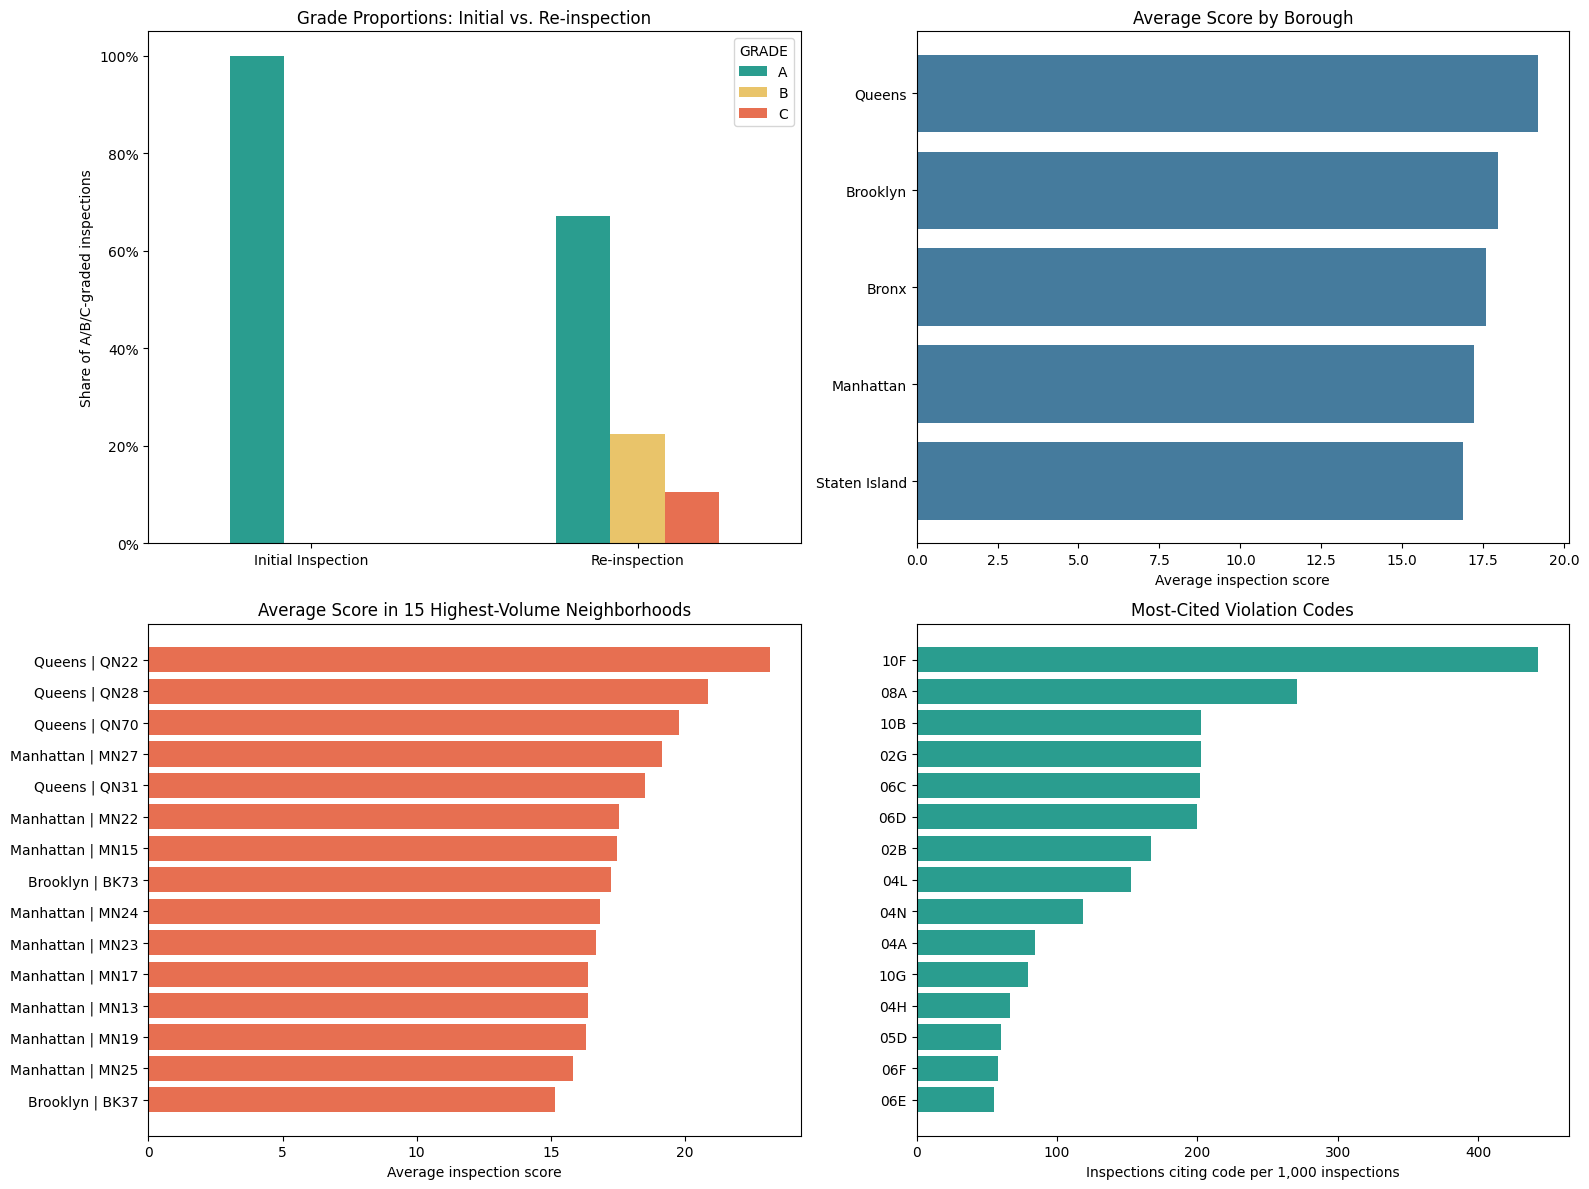

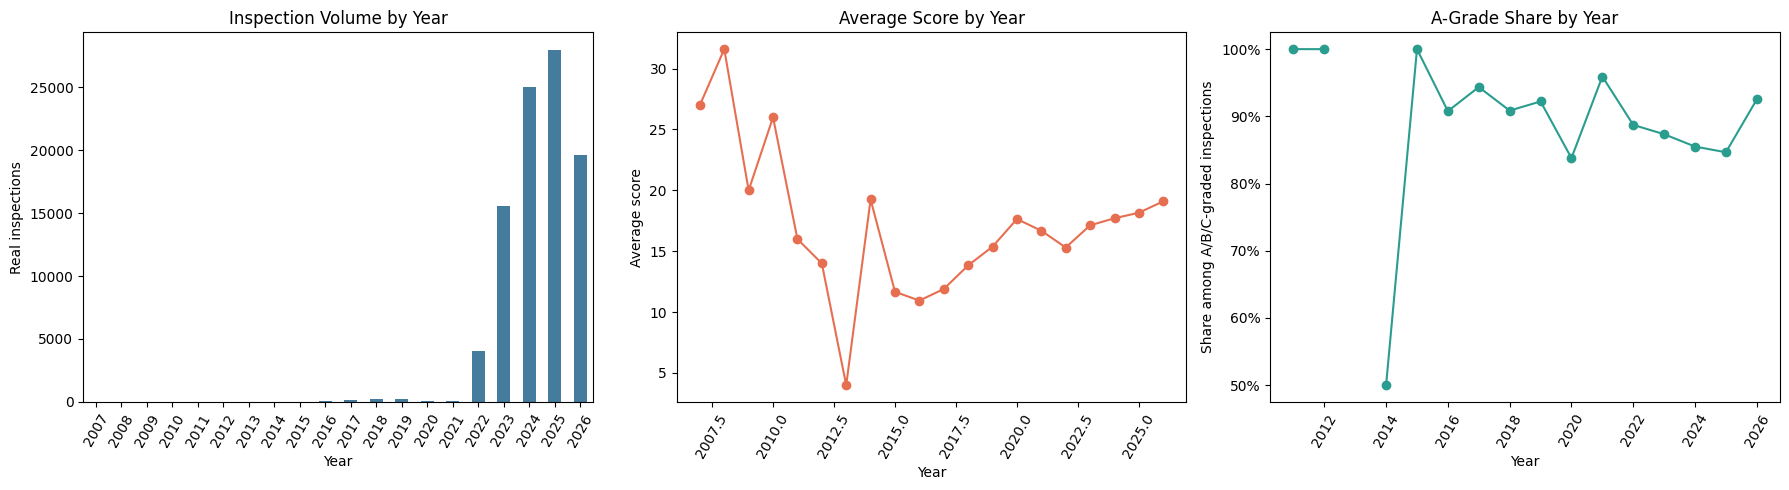

,year,total_inspections,scored_inspections,average_score,graded_inspections,a_grade_inspections,dohmh_closures,inspections_with_action,a_grade_share_among_graded,dohmh_closure_rate
0,2007,12,8,27.000000,0,0,0,12,NaN,0.000000
1,2008,6,5,31.600000,0,0,1,6,NaN,0.166667
2,2009,1,1,20.000000,0,0,0,1,NaN,0.000000
3,2010,4,2,26.000000,0,0,0,4,NaN,0.000000
4,2011,2,2,16.000000,1,1,0,2,1.000000,0.000000
5,2012,5,2,14.000000,1,1,0,5,1.000000,0.000000
6,2013,1,1,4.000000,0,0,0,1,NaN,0.000000
7,2014,5,4,19.250000,2,1,0,5,0.500000,0.000000
8,2015,10,9,11.666667,5,5,0,10,1.000000,0.000000
9,2016,102,92,10.945652,65,59,0,102,0.907692,0.000000


In [55]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

classified_initial_reinspection = initial_reinspection.loc[
    initial_reinspection["GRADE"].isin(["A", "B", "C"])
]
grade_proportions = pd.crosstab(
    classified_initial_reinspection["inspection_class"],
    classified_initial_reinspection["GRADE"],
    normalize="index",
).reindex(columns=["A", "B", "C"], fill_value=0)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
grade_proportions.plot(kind="bar", ax=axes[0, 0], color=["#2a9d8f", "#e9c46a", "#e76f51"])
axes[0, 0].set_title("Grade Proportions: Initial vs. Re-inspection")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Share of A/B/C-graded inspections")
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0, 0].tick_params(axis="x", rotation=0)

borough_plot = borough_summary.sort_values("average_score")
axes[0, 1].barh(borough_plot["BORO"], borough_plot["average_score"], color="#457b9d")
axes[0, 1].set_title("Average Score by Borough")
axes[0, 1].set_xlabel("Average inspection score")

neighborhood_plot = neighborhood_summary.head(15).copy()
neighborhood_plot["neighborhood_label"] = (
    neighborhood_plot["BORO"] + " | " + neighborhood_plot["NTA"]
)
neighborhood_plot = neighborhood_plot.sort_values("average_score")
axes[1, 0].barh(
    neighborhood_plot["neighborhood_label"],
    neighborhood_plot["average_score"],
    color="#e76f51",
)
axes[1, 0].set_title("Average Score in 15 Highest-Volume Neighborhoods")
axes[1, 0].set_xlabel("Average inspection score")

code_plot = top_violation_codes.head(15).sort_values("inspections_per_1000")
axes[1, 1].barh(
    code_plot["VIOLATION CODE"],
    code_plot["inspections_per_1000"],
    color="#2a9d8f",
)
axes[1, 1].set_title("Most-Cited Violation Codes")
axes[1, 1].set_xlabel("Inspections citing code per 1,000 inspections")

fig.tight_layout()
plt.show()

yearly_data = real_inspections.loc[real_inspections["INSPECTION DATE"].notna()].copy()
yearly_data["year"] = yearly_data["INSPECTION DATE"].dt.year
yearly_summary = (
    yearly_data.groupby("year")
    .agg(
        total_inspections=("CAMIS", "size"),
        scored_inspections=("SCORE", "count"),
        average_score=("SCORE", "mean"),
        graded_inspections=("GRADE", lambda grades: grades.isin(["A", "B", "C"]).sum()),
        a_grade_inspections=("GRADE", lambda grades: grades.eq("A").sum()),
        dohmh_closures=(
            "ACTION",
            lambda actions: actions.str.contains(
                r"Establishment (?:re-)?closed by DOHMH",
                case=False,
                regex=True,
                na=False,
            ).sum(),
        ),
        inspections_with_action=("ACTION", "count"),
    )
    .reset_index()
)
yearly_summary["a_grade_share_among_graded"] = (
    yearly_summary["a_grade_inspections"]
    / yearly_summary["graded_inspections"].replace(0, np.nan)
)
yearly_summary["dohmh_closure_rate"] = (
    yearly_summary["dohmh_closures"]
    / yearly_summary["inspections_with_action"].replace(0, np.nan)
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
yearly_summary.plot(x="year", y="total_inspections", kind="bar", ax=axes[0], legend=False, color="#457b9d")
axes[0].set_title("Inspection Volume by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Real inspections")
axes[0].tick_params(axis="x", rotation=60)

yearly_summary.plot(x="year", y="average_score", kind="line", marker="o", ax=axes[1], legend=False, color="#e76f51")
axes[1].set_title("Average Score by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Average score")
axes[1].tick_params(axis="x", rotation=60)

yearly_summary.plot(x="year", y="a_grade_share_among_graded", kind="line", marker="o", ax=axes[2], legend=False, color="#2a9d8f")
axes[2].set_title("A-Grade Share by Year")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Share among A/B/C-graded inspections")
axes[2].yaxis.set_major_formatter(PercentFormatter(1))
axes[2].tick_params(axis="x", rotation=60)

fig.tight_layout()
plt.show()
yearly_summary

### Geographic and Narrative Analysis

The geographic view plots each restaurant with at least one scored inspection at its available coordinates, colored by its mean inspection score. The text analysis groups recurring violation descriptions into exploratory TF-IDF/NMF topics; topics summarize wording patterns and are not official risk categories.

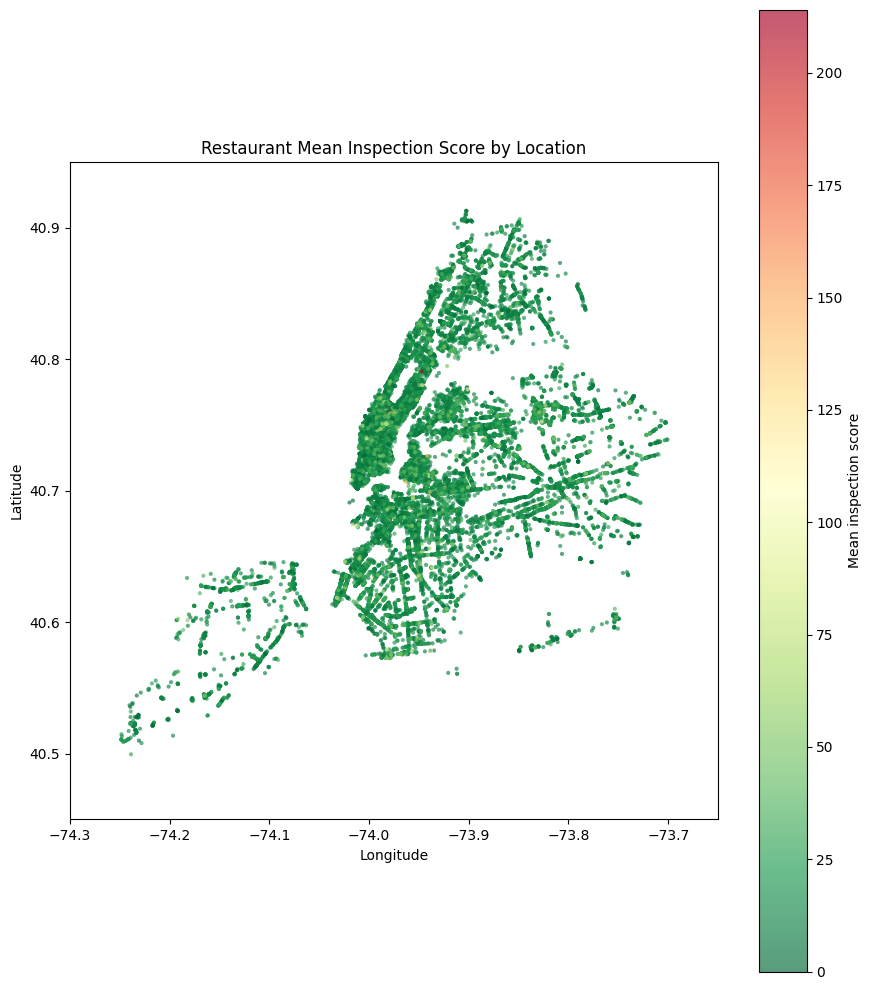

Restaurants plotted: 27053
Restaurants with scored inspections: 27647


In [56]:
restaurant_map_data = (
    scored_real_inspections.groupby("CAMIS")
    .agg(
        average_score=("SCORE", "mean"),
        scored_inspections=("SCORE", "count"),
        BORO=("BORO", "first"),
        NTA=("NTA", "first"),
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first"),
        BORO_UNKNOWN=("BORO_UNKNOWN", "max"),
    )
    .reset_index()
)
restaurant_map_data = restaurant_map_data.loc[
    restaurant_map_data["Latitude"].between(40.45, 40.95)
    & restaurant_map_data["Longitude"].between(-74.30, -73.65)
    & ~restaurant_map_data["BORO_UNKNOWN"]
]

fig, ax = plt.subplots(figsize=(9, 10))
map_points = ax.scatter(
    restaurant_map_data["Longitude"],
    restaurant_map_data["Latitude"],
    c=restaurant_map_data["average_score"],
    cmap="RdYlGn_r",
    s=9,
    alpha=0.65,
    linewidths=0,
)
ax.set_title("Restaurant Mean Inspection Score by Location")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-74.30, -73.65)
ax.set_ylim(40.45, 40.95)
ax.set_aspect(1 / np.cos(np.deg2rad(40.7)))
fig.colorbar(map_points, ax=ax, label="Mean inspection score")
fig.tight_layout()
plt.show()

print("Restaurants plotted:", len(restaurant_map_data))
print("Restaurants with scored inspections:", scored_real_inspections["CAMIS"].nunique())

,topic,top_terms,unique_descriptions,violation_records,representative_descriptions
3,4,"surface, contact surface, food contact, contac...",39,80078,Non-food contact surface improperly constructe...
4,5,"area, food, preparation, storage, hand, provid...",77,75976,"Food, food preparation area, food storage area..."
0,1,"held, food, hours, hot, tcs, food item, item, ...",54,63070,Hot TCS food item that has been cooked and coo...
2,3,"food, live, food non, non food, non, facility ...",20,59456,Live roaches present in facility's food and/or...
1,2,"posted, grade, sign, sign posted, letter grade...",44,10819,Current letter grade sign not posted. | Curren...


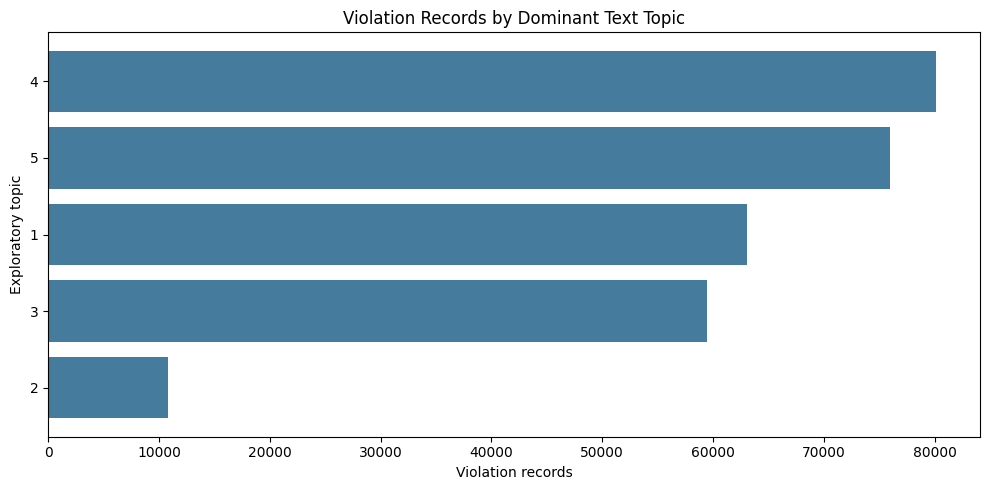

In [57]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

description_counts = (
    violation_rows["VIOLATION DESCRIPTION"]
    .dropna()
    .str.strip()
    .loc[lambda descriptions: descriptions.ne("")]
    .value_counts()
)
violation_documents = description_counts.index.to_list()
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_features=1500,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
)
tfidf_matrix = vectorizer.fit_transform(violation_documents)
topic_model = NMF(
    n_components=5,
    init="nndsvda",
    max_iter=500,
    random_state=42,
)
document_topic_weights = topic_model.fit_transform(tfidf_matrix)
feature_terms = vectorizer.get_feature_names_out()
dominant_topics = document_topic_weights.argmax(axis=1)

topic_rows = []
for topic_number, topic_weights in enumerate(topic_model.components_):
    top_term_indices = topic_weights.argsort()[::-1][:8]
    topic_documents_mask = dominant_topics == topic_number
    topic_document_indices = np.flatnonzero(topic_documents_mask)
    representative_indices = topic_document_indices[
        document_topic_weights[topic_document_indices, topic_number].argsort()[::-1][:3]
    ]
    topic_rows.append(
        {
            "topic": topic_number + 1,
            "top_terms": ", ".join(feature_terms[top_term_indices]),
            "unique_descriptions": int(topic_documents_mask.sum()),
            "violation_records": int(
                description_counts.iloc[topic_document_indices].sum()
            ),
            "representative_descriptions": " | ".join(
                violation_documents[index][:140] for index in representative_indices
            ),
        }
    )

violation_topics = pd.DataFrame(topic_rows).sort_values(
    "violation_records", ascending=False
)
display(violation_topics)

fig, ax = plt.subplots(figsize=(10, 5))
topic_plot = violation_topics.sort_values("violation_records")
ax.barh(topic_plot["topic"].astype(str), topic_plot["violation_records"], color="#457b9d")
ax.set_title("Violation Records by Dominant Text Topic")
ax.set_xlabel("Violation records")
ax.set_ylabel("Exploratory topic")
fig.tight_layout()
plt.show()

,year,total_inspections,scored_inspections,average_score,graded_inspections,a_grade_inspections,dohmh_closures,inspections_with_action,a_grade_share_among_graded,dohmh_closure_rate
15,2022,4009,3704,15.304536,2279,2022,63,4009,0.887231,0.015715
16,2023,15596,13964,17.126683,9019,7877,236,15596,0.873378,0.015132
17,2024,25034,22458,17.709680,14331,12253,494,25034,0.855000,0.019733
18,2025,27958,24641,18.162209,15514,13133,580,27958,0.846526,0.020745
19,2026,19648,17268,19.098448,9702,8977,503,19648,0.925273,0.025601


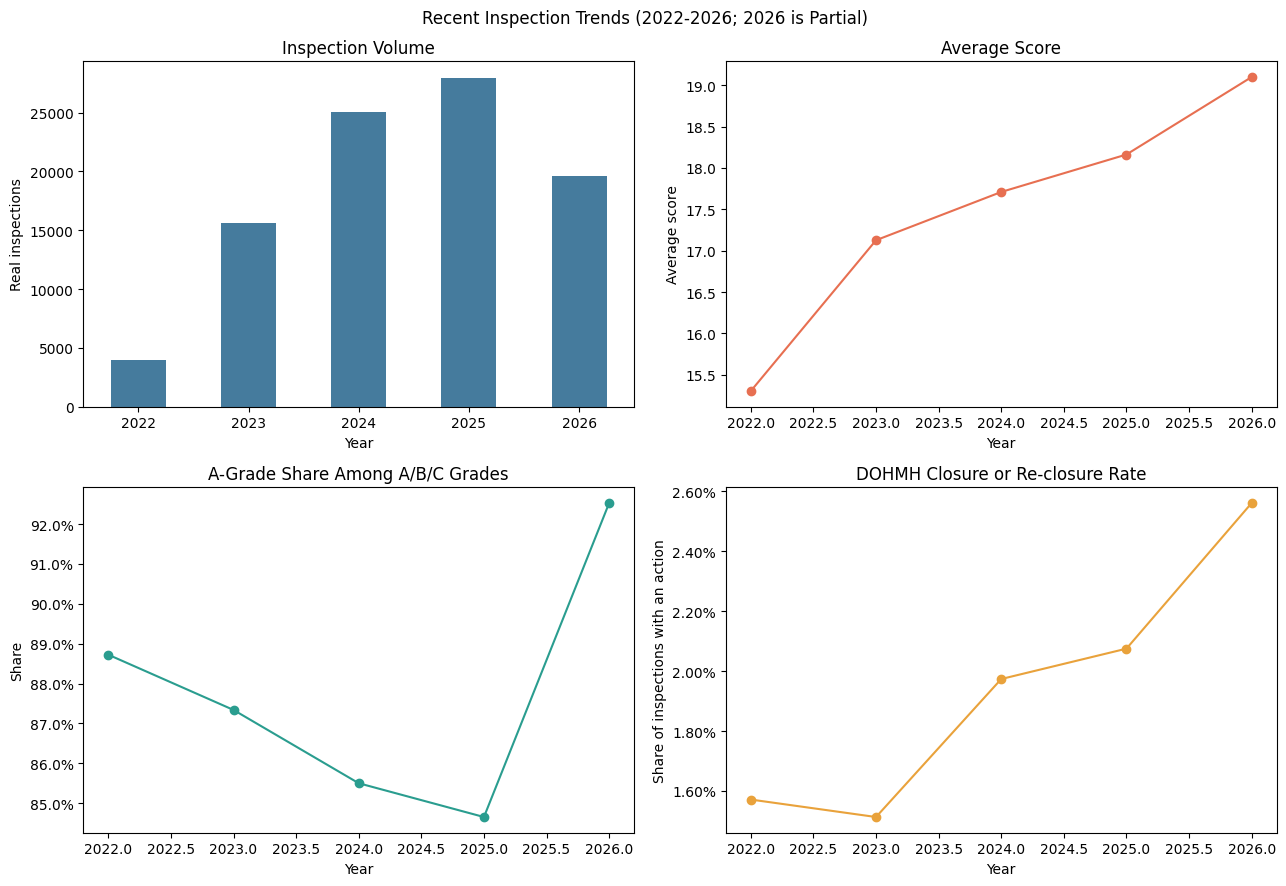

In [59]:
recent_yearly_summary = yearly_summary.loc[yearly_summary["year"] >= 2022].copy()
display(recent_yearly_summary)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
recent_yearly_summary.plot(
    x="year", y="total_inspections", kind="bar", ax=axes[0, 0], legend=False, color="#457b9d"
)
axes[0, 0].set_title("Inspection Volume")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Real inspections")
axes[0, 0].tick_params(axis="x", rotation=0)

recent_yearly_summary.plot(
    x="year", y="average_score", kind="line", marker="o", ax=axes[0, 1], legend=False, color="#e76f51"
)
axes[0, 1].set_title("Average Score")
axes[0, 1].set_xlabel("Year")
axes[0, 1].set_ylabel("Average score")
axes[0, 1].tick_params(axis="x", rotation=0)

recent_yearly_summary.plot(
    x="year", y="a_grade_share_among_graded", kind="line", marker="o", ax=axes[1, 0], legend=False, color="#2a9d8f"
)
axes[1, 0].set_title("A-Grade Share Among A/B/C Grades")
axes[1, 0].set_xlabel("Year")
axes[1, 0].set_ylabel("Share")
axes[1, 0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 0].tick_params(axis="x", rotation=0)

recent_yearly_summary.plot(
    x="year", y="dohmh_closure_rate", kind="line", marker="o", ax=axes[1, 1], legend=False, color="#e9a23b"
)
axes[1, 1].set_title("DOHMH Closure or Re-closure Rate")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Share of inspections with an action")
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 1].tick_params(axis="x", rotation=0)

fig.suptitle("Recent Inspection Trends (2022-2026; 2026 is Partial)")
fig.tight_layout()
plt.show()